# EMQA_L5_samuelson

**The Samuelson effect in TTF futures**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_samuelson/EMQA_L5_samuelson.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Volatility of two TTF contracts with different delivery months, measured over the same calendar days.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def legend_compact(fig, ncol):
    """Bottom legend with shorter handles and column gaps, for many short entries."""
    legend_bottom(fig, ncol=ncol)
    h, l = fig.legends[-1].legend_handles, [t.get_text() for t in fig.legends[-1].get_texts()]
    fig.legends[-1].remove()
    fig.legend(h, l, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=1.0, handletextpad=0.4, columnspacing=0.9)


def save_chart(fig, name):
    """Keep under the axes exactly the height of the bottom legend, then save the PNG."""
    fig.canvas.draw()
    bottom = max([lg.get_window_extent().height / fig.bbox.height + 0.035 for lg in fig.legends] or [0.0])
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + '.png', dpi=150, bbox_inches='tight', transparent=True)
    plt.show()


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
TTFC = pd.read_csv(DATA + 'ttf_futures_contracts_daily.csv', parse_dates=['date']).set_index('date').loc[:END]


def ann_vol(s, window=None):
    """Daily log returns between consecutive trading days (gaps <= 4 calendar days); with window: rolling annualised vol."""
    s = s.dropna()
    r = np.log(s).diff().dropna()
    gap = s.index.to_series().diff().dt.days.reindex(r.index)
    r = r[gap <= 4]
    return r if window is None else r.rolling(window).std() * np.sqrt(252)


W12 = (END - pd.DateOffset(months=12) + pd.Timedelta(days=1)).normalize()
show('window of the last 12 months: from', d(W12), 'sam.w_from')
show('                               to', d(END), 'sam.w_to')
for c in TTFC.columns:
    r = ann_vol(TTFC[c])
    show(f'TTF {c}: volatility last 12 months, % per year', r.loc[W12:END].std() * np.sqrt(252) * 100, f'sam.{c}.v12', '.1f')
    show(f'TTF {c}: volatility in 2022, % per year', r.loc['2022'].std() * np.sqrt(252) * 100, f'sam.{c}.v22', '.1f')
ROLLV = pd.DataFrame({c: ann_vol(TTFC[c], 60) for c in ['2026-12', '2027-05']})

window of the last 12 months: from                           2025-11-01   [sam.w_from]
                               to                            2026-10-31   [sam.w_to]
TTF 2026-12: volatility last 12 months, % per year                 63.0   [sam.2026-12.v12]
TTF 2026-12: volatility in 2022, % per year                        66.1   [sam.2026-12.v22]
TTF 2027-01: volatility last 12 months, % per year                 61.2   [sam.2027-01.v12]
TTF 2027-01: volatility in 2022, % per year                        67.8   [sam.2027-01.v22]
TTF 2027-02: volatility last 12 months, % per year                 67.7   [sam.2027-02.v12]
TTF 2027-02: volatility in 2022, % per year                        69.2   [sam.2027-02.v22]
TTF 2027-05: volatility last 12 months, % per year                 47.7   [sam.2027-05.v12]
TTF 2027-05: volatility in 2022, % per year                        66.8   [sam.2027-05.v22]


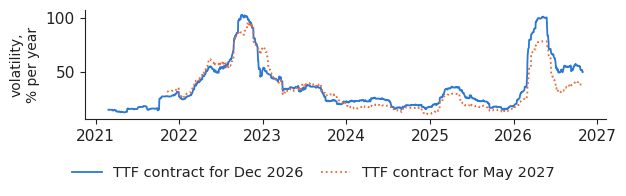

In [5]:
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
fig, ax = plt.subplots(figsize=(6.4, 2.0))
for c, cc, ls in [('2026-12', PAL['RO'], '-'), ('2027-05', PAL['DE_LU'], ':')]:
    v = ROLLV[c].dropna() * 100
    ax.plot(v.index, v.values, color=cc, ls=ls, lw=1.3, label='TTF contract for ' + MON[int(c[5:]) - 1] + ' ' + c[:4])
ax.set_ylabel('volatility,\n% per year', fontsize=10)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
legend_bottom(fig, ncol=2)
save_chart(fig, 'samuelson')